# Mini Project: Big Data Analytics
## Part 1: Deep Learning Image Classification บน Kaggle (ใช้ GPU)

**ชื่อ-สกุล:** เนตรทิพย์ พรหมสิทธิ์  **รหัสนักศึกษา:** 663020275-1

**ชุดข้อมูลที่ใช้:** 5 Flower Types Classification (Kaggle) — ดอกไม้ 5 class: Lily, Lotus, Sunflower, Orchid, Tulip (class ละประมาณ 1,000 ภาพ) ลิงก์: https://www.kaggle.com/datasets/kausthubkannan/5-flower-types-classification-dataset

**ลิงก์ Kaggle Notebook (Public):** https://www.kaggle.com/code/netthipphommasit/663020275-1-project2-individual
**กำหนดส่ง Part 1:** ...

---
### ⚠️ NOTE (สำคัญมาก)
* **ลิงก์ต้องเปิดได้ (Public) ถ้าอาจารย์เปิดไม่ได้ Part 1 ได้ 0 คะแนน** ทดสอบใน Incognito ก่อนส่งทุกครั้ง
* ต้องเป็นเวอร์ชันที่ **Save & Run All (Commit) สำเร็จ** และมีผลลัพธ์ทุกเซลล์
* ยืนยันเบอร์โทรในบัญชี Kaggle (จำเป็นสำหรับ GPU และ Internet)
* GPU มีโควตาจำกัดต่อสัปดาห์ ทดลองกับ epoch น้อย ๆ ก่อน

## สิ่งที่ต้องทำใน Part 1

1. **เลือกชุดข้อมูลภาพสาธารณะ 1 ชุดจาก [Kaggle Datasets](https://www.kaggle.com/datasets)** (แจ้งชื่อชุดข้อมูลกับอาจารย์ ห้ามซ้ำกับกลุ่มอื่น)
   * อย่างน้อย 3 classes และอย่างน้อย 2,000 ภาพ
   * ห้ามใช้ CIFAR-10 / MNIST / Fashion-MNIST (ใช้ในตัวอย่างแล้ว)
   * ตัวอย่างแนวที่เหมาะ: โรคใบพืช, ชนิดขยะรีไซเคิล, ภาพเอกซเรย์ปอด, ชนิดอาหาร, ภาพดาวเทียมการใช้ที่ดิน, ดอกไม้, ป้ายจราจร
2. **ใช้ GPU** และแสดงผลยืนยันว่าเทรนบน GPU
3. **ออกแบบ data augmentation เอง** ให้เหมาะกับภาพของกลุ่ม พร้อมเหตุผลทุกข้อ และแสดงตัวอย่างภาพหลัง augment
   (ระวัง augmentation ที่เปลี่ยนความหมายของภาพ เช่น พลิกป้ายจราจรซ้ายขวา หรือหมุนภาพเอกซเรย์กลับหัว)
4. **ทดลองเทรนอย่างน้อย 2 การทดลอง** ด้วยการตั้งค่าอื่นเหมือนกันทุกอย่าง
   * **A: ไม่ augment**
   * **B: augment ตามที่กลุ่มออกแบบ**
   * (ไม่บังคับ) **C:** การทดลองเพิ่มเติมของกลุ่ม เช่น augment แรงขึ้น, เปลี่ยน learning rate, เปลี่ยนโมเดล
5. **เทรนให้นานพอจน converge:** validation loss ต้องนิ่งหรือเริ่มเพิ่มขึ้นจน early stopping หยุดเอง
   ถ้าเทรนครบทุก epoch แล้ว val loss ยังลดลงอยู่ ให้เพิ่ม `epochs` แล้วเทรนใหม่
6. **Checkpoint:** บันทึก `last.pt` ทุก epoch และ `best.pt` เมื่อ validation loss ดีขึ้น แยกโฟลเดอร์ตามการทดลอง พร้อม **สาธิตการ resume**
7. **Loss curve:** กราฟ train vs validation loss และ accuracy ของทุกการทดลอง พร้อมตารางเปรียบเทียบ
8. **เลือกโมเดลสุดท้ายจาก validation loss** แล้วประเมินบน test set **ครั้งเดียว**: accuracy, precision/recall/F1 ราย class, confusion matrix และตัวอย่างภาพที่ทำนายผิด
9. **อภิปรายผล** ตามคำถามในหัวข้อสุดท้าย

### เกณฑ์การให้คะแนน (100 คะแนน)
| รายการ | คะแนน |
|---|---|
| **เงื่อนไขผ่าน:** ลิงก์ Public เปิดได้ และ Run All สำเร็จ | ไม่ผ่าน = 0 ทั้ง Part |
| ใช้ GPU และตั้งค่าถูกต้อง | 5 |
| การเตรียมข้อมูล (stratified split, สำรวจข้อมูล) | 10 |
| ออกแบบ augmentation พร้อมเหตุผลและตัวอย่างภาพ | 15 |
| Checkpoint + resume + early stopping | 15 |
| การทดลอง A vs B ที่ converge, loss curve และตารางเปรียบเทียบ | 25 |
| เลือกโมเดลและประเมินบน test set | 20 |
| อภิปรายผล | 10 |

---
## ขั้นตอนตั้งค่า Kaggle ก่อนเริ่ม
1. Kaggle > **Code** > **New Notebook** (หรือ File > Import Notebook แล้วเลือกไฟล์ .ipynb นี้)
2. แผงขวา **Session options** > **Accelerator** > เลือก **GPU T4 x2** หรือ **GPU P100**
3. **Internet: On** (ใช้ดาวน์โหลด pretrained weights)
4. เพิ่มชุดข้อมูล: **+ Add Input** > ค้นหาชื่อ dataset > Add (ไฟล์จะอยู่ที่ `/kaggle/input/...`)
5. เพิ่มเพื่อนในกลุ่ม: **Share** > **Add collaborators** เพื่อทำงานใน notebook เดียวกัน

> ตัวอย่างด้านล่างใช้ CIFAR-10 (`USE_DEMO = True`) เพื่อให้รันได้ทันที **ของจริงให้ตั้ง `USE_DEMO = False` ใส่ `DATA_DIR` และออกแบบ `aug_tf` ของกลุ่มเอง**

## 1. Setup และตรวจสอบ GPU

In [31]:
import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "ยังไม่ได้เปิด GPU: Session options > Accelerator > GPU"
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
!nvidia-smi

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Tue Oct 27 05:33:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   76C    P0             29W /   70W |    1887MiB /  15360MiB |      0%      Default |
|                                         |                        |               

In [32]:
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

CFG = {
    "img_size": 224,
    "batch_size": 64,
    "epochs": 40,           # จำนวน epoch สูงสุด (ตั้งให้พอให้ early stopping หยุดเองได้)
    "patience": 5,          # early stopping: หยุดเมื่อ val loss ไม่ดีขึ้น 5 epochs ติดกัน
    "lr": 3e-4,
    "weight_decay": 1e-4,
    "val_ratio": 0.15,
    "test_ratio": 0.15,
    "num_workers": 2,
}
WORK_DIR = "/kaggle/working"
CKPT_DIR = f"{WORK_DIR}/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

## 2. Data Loading และ Data Preparation
* แบ่งข้อมูลแบบ **stratified** 70/15/15 เพื่อให้สัดส่วนแต่ละ class เท่ากันทุกชุด
* validation/test ใช้แค่ resize + normalize เสมอ (augment เฉพาะ train set)

In [33]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ค่าของ ImageNet (ใช้กับ pretrained model)
S = CFG["img_size"]
eval_tf = transforms.Compose([
    transforms.Resize((S, S)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

USE_DEMO = False
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def find_class_root(base="/kaggle/input", min_classes=3):
    """หาโฟลเดอร์ที่ทุกโฟลเดอร์ย่อยเป็น class (มีไฟล์ภาพอยู่ข้างใน)
    ถ้าเจอหลายที่ (เช่น dataset ที่แบ่ง train/test ไว้แล้ว) จะเลือกที่มีภาพรวมมากที่สุด"""
    best, best_n = None, 0
    for root, dirs, _ in os.walk(base):
        if len(dirs) < min_classes: continue
        counts = []
        for d in dirs:
            p = os.path.join(root, d)
            counts.append(sum(f.lower().endswith(IMG_EXT) for f in os.listdir(p)))
        if all(c > 0 for c in counts) and sum(counts) > best_n:
            best, best_n = root, sum(counts)
    if best is None:
        raise FileNotFoundError("ไม่พบโฟลเดอร์ class: กด + Add Input เพิ่ม dataset ก่อน แล้วเช็กโครงสร้างโฟลเดอร์")
    return best

DATA_DIR = find_class_root()
print("DATA_DIR =", DATA_DIR)

def make_full_dataset(tf):
    if USE_DEMO:
        return datasets.CIFAR10(f"{WORK_DIR}/data", train=True, download=True, transform=tf)
    return datasets.ImageFolder(DATA_DIR, transform=tf)

def stratified_split(idx, targets, val_ratio, test_ratio, seed=SEED):
    pos = np.arange(len(idx))
    tr, tmp = train_test_split(pos, test_size=val_ratio + test_ratio, stratify=targets, random_state=seed)
    va, te = train_test_split(tmp, test_size=test_ratio / (val_ratio + test_ratio),
                              stratify=targets[tmp], random_state=seed)
    return idx[tr], idx[va], idx[te]

full_eval = make_full_dataset(eval_tf)
class_names = full_eval.classes
NUM_CLASSES = len(class_names)
all_targets = np.array(full_eval.targets)

# ตรวจเงื่อนไขของอาจารย์: >= 3 classes และ >= 2,000 ภาพ
assert NUM_CLASSES >= 3, f"ต้องมีอย่างน้อย 3 classes (พบ {NUM_CLASSES})"
assert len(full_eval) >= 2000, f"ต้องมีอย่างน้อย 2,000 ภาพ (พบ {len(full_eval)})"

pool = np.arange(len(full_eval))
train_idx, val_idx, test_idx = stratified_split(pool, all_targets[pool], CFG["val_ratio"], CFG["test_ratio"])
# หมายเหตุ: ถ้า dataset แบ่ง train/test มาให้แล้ว ให้ใช้ test ที่ให้มา และแบ่ง validation จาก train

val_ds  = Subset(full_eval, val_idx)
test_ds = Subset(full_eval, test_idx)
print("classes:", class_names)
print(f"total={len(full_eval):,}  train={len(train_idx):,}  val={len(val_idx):,}  test={len(test_idx):,}")


DATA_DIR = /kaggle/input/datasets/kausthubkannan/5-flower-types-classification-dataset/flower_images
classes: ['Lilly', 'Lotus', 'Orchid', 'Sunflower', 'Tulip']
total=4,999  train=3,499  val=750  test=750


### ตรวจภาพซ้ำข้าม train/val/test (data leakage)
ชุดข้อมูลที่เก็บจากเว็บอาจมีภาพซ้ำ ถ้าภาพเดียวกันอยู่ทั้ง train และ test ผลจะดีเกินจริง

In [34]:
import hashlib
def file_hash(path):
    with open(path, "rb") as f: return hashlib.md5(f.read()).hexdigest()

hashes = [file_hash(p) for p, _ in full_eval.samples]
split_of = {}
for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    for i in idx: split_of[i] = name

from collections import defaultdict
groups = defaultdict(list)
for i, h in enumerate(hashes): groups[h].append(i)
dups = [g for g in groups.values() if len(g) > 1]
leaks = [g for g in dups if len({split_of[i] for i in g}) > 1]
print(f"กลุ่มภาพซ้ำ (ไฟล์เหมือนกันทุกไบต์): {len(dups)} กลุ่ม | ซ้ำข้าม split: {len(leaks)} กลุ่ม")
# ถ้ามี leak ให้ลบภาพซ้ำออกจาก val/test (เก็บไว้ใน train) แล้วรายงานจำนวนที่ตัดออก
if leaks:
    drop = {i for g in leaks for i in g if split_of[i] != "train"}
    val_idx  = np.array([i for i in val_idx  if i not in drop])
    test_idx = np.array([i for i in test_idx if i not in drop])
    val_ds, test_ds = Subset(full_eval, val_idx), Subset(full_eval, test_idx)
    print(f"ตัดภาพซ้ำออกจาก val/test {len(drop)} ภาพ -> val={len(val_idx)} test={len(test_idx)}")


กลุ่มภาพซ้ำ (ไฟล์เหมือนกันทุกไบต์): 14 กลุ่ม | ซ้ำข้าม split: 5 กลุ่ม
ตัดภาพซ้ำออกจาก val/test 5 ภาพ -> val=745 test=750


### สำรวจข้อมูล: การกระจายของ class และตัวอย่างภาพ

,all,train,val,test,% of all
Lilly,999,699,149,150,20.0
Lotus,1000,700,149,150,20.0
Orchid,1000,700,149,150,20.0
Sunflower,1000,700,150,150,20.0
Tulip,1000,700,148,150,20.0


imbalance ratio (มากสุด/น้อยสุด) = 1.00
ขนาดภาพต้นฉบับ (กว้าง, สูง) จากการสุ่ม 200 ภาพ:
(275, 183)    20
(225, 225)    17
(300, 168)    15
(284, 177)     5
(299, 168)     3
Name: count, dtype: int64


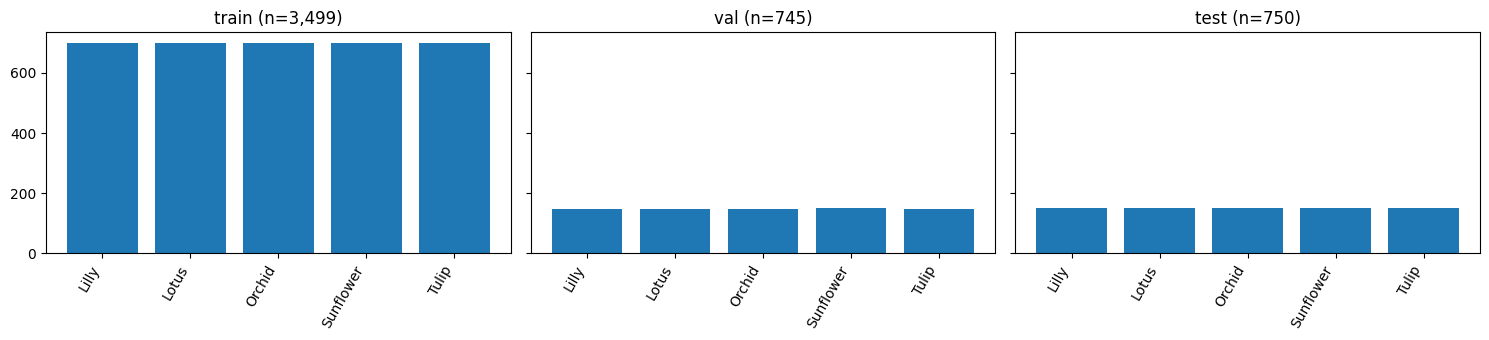

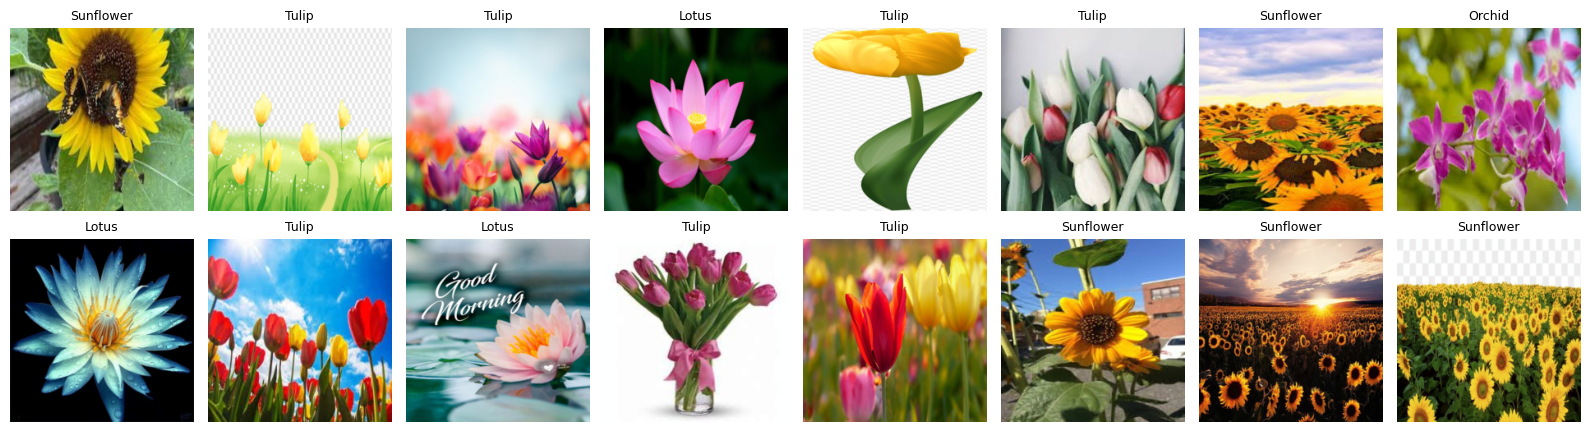

In [35]:
counts_df = pd.DataFrame({name: np.bincount(all_targets[idx], minlength=NUM_CLASSES)
                          for name, idx in [("all", pool), ("train", train_idx), ("val", val_idx), ("test", test_idx)]},
                         index=class_names)
counts_df["% of all"] = (100 * counts_df["all"] / counts_df["all"].sum()).round(1)
display(counts_df)
print(f"imbalance ratio (มากสุด/น้อยสุด) = {counts_df['all'].max() / counts_df['all'].min():.2f}")

from PIL import Image
sample = np.random.default_rng(SEED).choice(len(full_eval), min(200, len(full_eval)), replace=False)
sizes = pd.Series([Image.open(full_eval.samples[i][0]).size for i in sample]).value_counts()
print("ขนาดภาพต้นฉบับ (กว้าง, สูง) จากการสุ่ม 200 ภาพ:"); print(sizes.head())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for a, (name, idx) in zip(ax, [("train", train_idx), ("val", val_idx), ("test", test_idx)]):
    counts = np.bincount(all_targets[idx], minlength=NUM_CLASSES)
    a.bar(range(NUM_CLASSES), counts); a.set_title(f"{name} (n={len(idx):,})")
    a.set_xticks(range(NUM_CLASSES)); a.set_xticklabels(class_names, rotation=60, ha="right")
plt.tight_layout(); plt.show()

def denorm(x):
    x = x.cpu().numpy().transpose(1, 2, 0) * np.array(STD) + np.array(MEAN)
    return np.clip(x, 0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for a, i in zip(axes.ravel(), np.random.choice(len(val_ds), 16, replace=False)):
    img, y = val_ds[i]
    a.imshow(denorm(img)); a.set_title(class_names[y], fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Data Augmentation (ออกแบบเอง)
**ลักษณะภาพ:** ภาพถ่ายดอกไม้ 5 ชนิด (ลิลลี่ บัว ทานตะวัน กล้วยไม้ ทิวลิป) ถ่ายด้วยระยะ มุมกล้อง และแสงต่างกัน ภาพจริงอาจมีดอกหลายดอก ใบ ก้าน น้ำ หรือพื้นหลังรกปนอยู่ (ให้ดูภาพตัวอย่างด้านบนแล้วปรับข้อความนี้ให้ตรงกับที่เห็นจริง)

| Augmentation | ค่าที่ใช้ | เหตุผล (ภาพจริงมีความแปรผันแบบนี้หรือไม่) |
|---|---|---|
| `RandomResizedCrop` | scale = (0.7, 1.0) | ระยะกล้องและตำแหน่งดอกในภาพต่างกัน; ไม่ครอปต่ำกว่า 70% เพราะอาจเหลือแต่ใบ/ก้านซึ่งไม่บอก class |
| `RandomHorizontalFlip` | p = 0.5 | ดอกไม้ไม่มีด้านซ้าย/ขวาที่มีความหมาย พลิกแล้วยังเป็นดอกชนิดเดิม |
| `RandomRotation` | ±20° | ถ่ายเอียงมือถือ/ดอกเอนตามลม; จำกัดมุมเพื่อไม่ให้มุมดำกินพื้นที่ |
| `ColorJitter` | brightness/contrast 0.25, saturation 0.15, hue 0.02 | แสงแดด/ร่ม/เวลาถ่ายต่างกัน; hue น้อยมากเพราะสีกลีบเป็นเบาะแสของบางชนิด (เช่น ทานตะวันสีเหลือง) |
| ไม่ใช้ `RandomVerticalFlip` | – | ภาพส่วนใหญ่มีทิศบน-ล่างตามธรรมชาติ (ก้านและพื้น/น้ำอยู่ล่าง) การกลับหัวทำให้ภาพไม่เหมือนภาพจริงตอนใช้งาน (ตรวจจากภาพตัวอย่างอีกครั้ง) |
| ไม่ใช้ Grayscale | – | สีกลีบช่วยแยกชนิด จึงไม่ตัดสี |

**การทดลอง C (เพิ่มเติม):** augment แรงขึ้น (ครอป 0.5–1.0, หมุน ±30°, jitter แรงขึ้น, `RandomErasing` จำลองดอกถูกบังบางส่วน) เพื่อดูว่าช่วยหรือทำให้ underfit


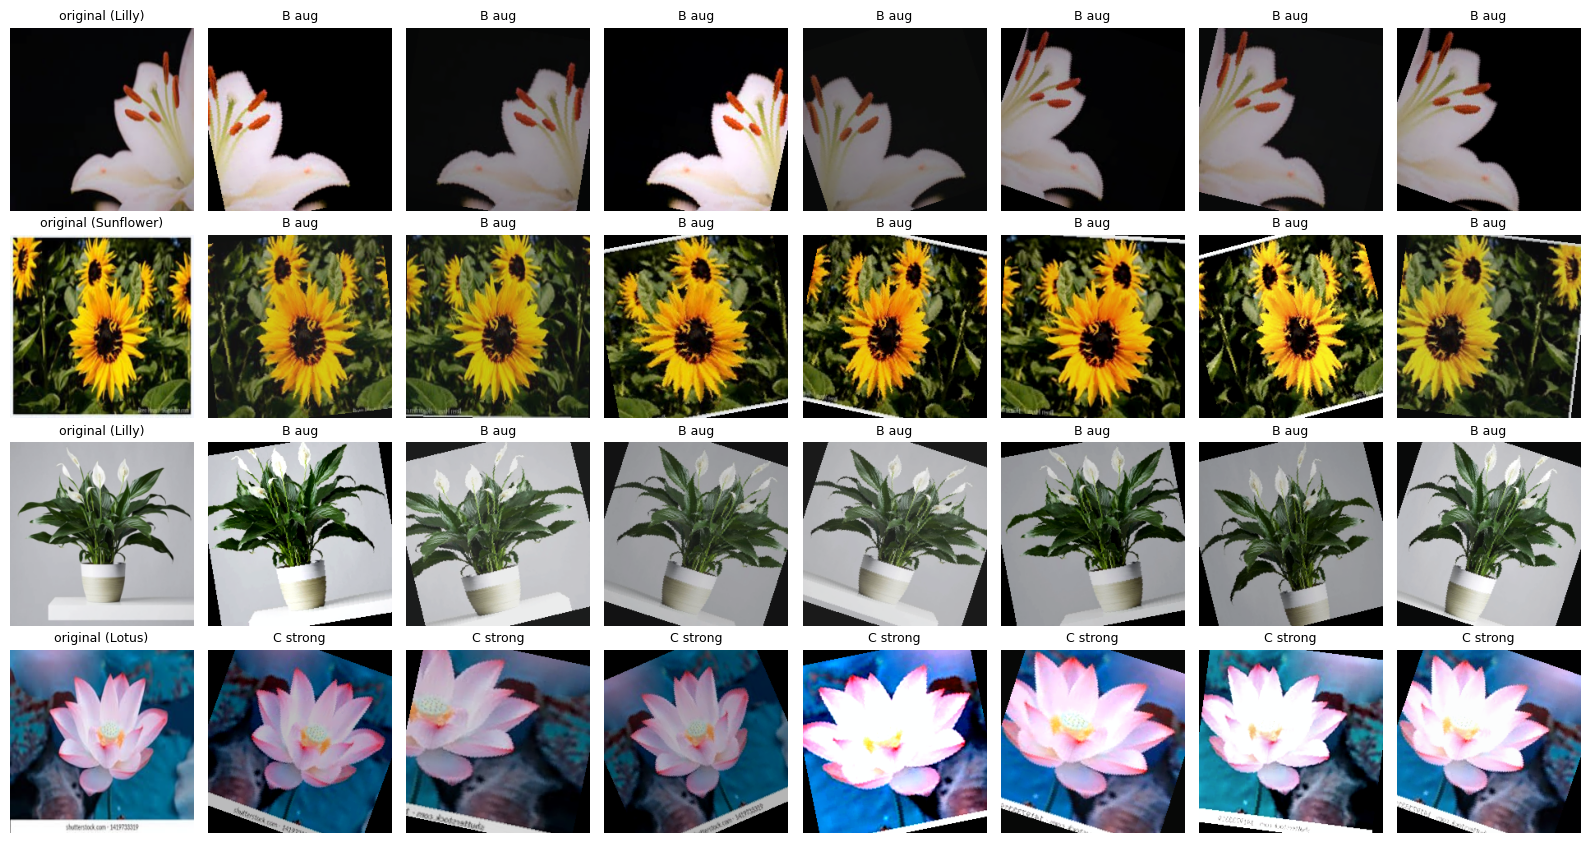

In [36]:
aug_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

strong_aug_tf = transforms.Compose([      # การทดลอง C
    transforms.RandomResizedCrop(S, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.25, hue=0.03),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])

full_aug = make_full_dataset(aug_tf)
full_strong = make_full_dataset(strong_aug_tf)
train_ds = {
    "A_no_aug":     Subset(full_eval,   train_idx),
    "B_aug":        Subset(full_aug,    train_idx),
    "C_strong_aug": Subset(full_strong, train_idx),
}

# ตัวอย่างภาพหลัง augment: แถวละ 1 ภาพต้นฉบับ + 7 แบบที่ถูก augment (แถว 1-3 = B, แถว 4 = C)
rng = np.random.default_rng(SEED)
picks = rng.choice(train_idx, 4, replace=False)
fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))
for r, (row, i) in enumerate(zip(axes, picks)):
    ds_aug, tag = (full_aug, "B aug") if r < 3 else (full_strong, "C strong")
    row[0].imshow(denorm(full_eval[i][0])); row[0].set_title(f"original ({class_names[all_targets[i]]})", fontsize=9)
    for a in row[1:]:
        a.imshow(denorm(ds_aug[i][0])); a.set_title(tag, fontsize=9)
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()


In [37]:
loader_kw = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"], pin_memory=True)
val_loader  = DataLoader(val_ds,  shuffle=False, **loader_kw)
test_loader = DataLoader(test_ds, shuffle=False, **loader_kw)
def make_train_loader(exp):
    set_seed()   # ลำดับข้อมูลเหมือนกันทุกการทดลอง เพื่อการเปรียบเทียบที่ยุติธรรม
    return DataLoader(train_ds[exp], shuffle=True, **loader_kw)

## 4. Model: Transfer Learning ด้วย ResNet-18
ใช้ pretrained weights จาก ImageNet แล้วเปลี่ยนชั้นสุดท้ายให้เท่ากับจำนวน class
(กลุ่มสามารถเปลี่ยนเป็น EfficientNet, MobileNet, ConvNeXt ฯลฯ ได้ แต่ต้องใช้โมเดลเดียวกันในการทดลอง A และ B)

In [38]:
def build_model(pretrained=True):
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
    return m.to(device)

def build_training_objects(model):
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG["epochs"])
    scaler = torch.amp.GradScaler("cuda")   # mixed precision: เร็วขึ้นและใช้หน่วยความจำ GPU น้อยลง
    return optimizer, scheduler, scaler

criterion = nn.CrossEntropyLoss()

## 5. Checkpoint
แต่ละ checkpoint เก็บ **model + optimizer + scheduler + scaler + history + epoch** เพื่อให้เทรนต่อได้เหมือนไม่เคยหยุด
* `checkpoints/<การทดลอง>/last.pt` บันทึกทุก epoch (ใช้ resume เมื่อ session หลุดหรือหมดเวลา)
* `checkpoints/<การทดลอง>/best.pt` บันทึกเมื่อ validation loss ต่ำที่สุด (ใช้ประเมินผลและนำไปใช้งาน)

In [39]:
def ckpt_paths(exp):
    d = f"{CKPT_DIR}/{exp}"; os.makedirs(d, exist_ok=True)
    return f"{d}/last.pt", f"{d}/best.pt"

def save_checkpoint(path, epoch, model, optimizer, scheduler, scaler, history, best_val_loss, bad_epochs, stopped_early):
    torch.save({
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "history": history,
        "best_val_loss": best_val_loss,
        "bad_epochs": bad_epochs,
        "stopped_early": stopped_early,
        "class_names": class_names,
        "cfg": CFG,
    }, path)

def load_checkpoint(path, model, optimizer=None, scheduler=None, scaler=None):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None: optimizer.load_state_dict(ckpt["optimizer_state"])
    if scheduler is not None: scheduler.load_state_dict(ckpt["scheduler_state"])
    if scaler is not None:    scaler.load_state_dict(ckpt["scaler_state"])
    return ckpt

## 6. Training loop (resume อัตโนมัติถ้ามี `last.pt`)

In [40]:
def run_epoch(model, loader, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.amp.autocast("cuda"):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def train_model(exp, until_epoch=None):
    until_epoch = until_epoch or CFG["epochs"]
    last_path, best_path = ckpt_paths(exp)
    set_seed()
    model = build_model()
    optimizer, scheduler, scaler = build_training_objects(model)
    train_loader = make_train_loader(exp)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
    start_epoch, best_val_loss, bad_epochs, stopped_early = 1, float("inf"), 0, False
    if os.path.exists(last_path):   # ---- RESUME ----
        ckpt = load_checkpoint(last_path, model, optimizer, scheduler, scaler)
        start_epoch = ckpt["epoch"] + 1
        history, best_val_loss = ckpt["history"], ckpt["best_val_loss"]
        bad_epochs, stopped_early = ckpt["bad_epochs"], ckpt["stopped_early"]
        print(f"[{exp}] Resumed from {last_path}: epoch {ckpt['epoch']} เสร็จแล้ว, best_val_loss={best_val_loss:.4f}")
        if stopped_early:
            print(f"[{exp}] การทดลองนี้ early stop ไปแล้ว ไม่ต้องเทรนต่อ"); return history

    for epoch in range(start_epoch, until_epoch + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader)
        lr = optimizer.param_groups[0]["lr"]
        scheduler.step()
        for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc, lr]):
            history[k].append(v)

        improved = va_loss < best_val_loss
        if improved:
            best_val_loss, bad_epochs = va_loss, 0
        else:
            bad_epochs += 1
        stopped_early = bad_epochs >= CFG["patience"]
        state = (model, optimizer, scheduler, scaler, history, best_val_loss, bad_epochs, stopped_early)
        save_checkpoint(last_path, epoch, *state)
        if improved:
            save_checkpoint(best_path, epoch, *state)

        print(f"[{exp}] Epoch {epoch:02d}/{CFG['epochs']} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.3f} | lr {lr:.2e} | {time.time()-t0:.0f}s"
              + ("  <- best" if improved else ""))
        if stopped_early:
            print(f"[{exp}] Early stopping: val loss ไม่ดีขึ้น {CFG['patience']} epochs ติดกัน"); break

    best_ep = int(np.argmin(history["val_loss"])) + 1
    if not stopped_early and best_ep >= len(history["val_loss"]) - 1:
        print(f"[{exp}] ⚠️ val loss ยังลดลงอยู่ช่วงท้าย อาจยังไม่ converge: พิจารณาเพิ่ม CFG['epochs']")
    return history

histories = {}

### ล้าง checkpoint เก่าก่อนเริ่มเทรน
เพื่อให้ทุกครั้งที่ Run All เห็นการเทรนตั้งแต่ epoch 1 (ถ้ามีไฟล์ `last.pt` ค้าง โค้ดจะ resume จากไฟล์นั้นแทน) การสาธิต resume ทำในการทดลอง B ด้านล่าง

In [41]:
import shutil
shutil.rmtree(CKPT_DIR, ignore_errors=True); os.makedirs(CKPT_DIR, exist_ok=True)
print("ล้าง checkpoint เก่าแล้ว: ทุกการทดลองจะเริ่มจาก epoch 1")

ล้าง checkpoint เก่าแล้ว: ทุกการทดลองจะเริ่มจาก epoch 1


### 6.1 การทดลอง A: ไม่ augment

In [42]:
histories["A_no_aug"] = train_model("A_no_aug")

[A_no_aug] Epoch 01/40 | train loss 0.3531 acc 0.869 | val loss 0.2427 acc 0.915 | lr 3.00e-04 | 18s  <- best
[A_no_aug] Epoch 02/40 | train loss 0.0731 acc 0.978 | val loss 0.1979 acc 0.942 | lr 3.00e-04 | 18s  <- best
[A_no_aug] Epoch 03/40 | train loss 0.0449 acc 0.987 | val loss 0.3195 acc 0.926 | lr 2.98e-04 | 19s
[A_no_aug] Epoch 04/40 | train loss 0.0378 acc 0.989 | val loss 0.2818 acc 0.937 | lr 2.96e-04 | 19s
[A_no_aug] Epoch 05/40 | train loss 0.0220 acc 0.994 | val loss 0.2646 acc 0.948 | lr 2.93e-04 | 19s
[A_no_aug] Epoch 06/40 | train loss 0.0162 acc 0.994 | val loss 0.2674 acc 0.940 | lr 2.89e-04 | 18s
[A_no_aug] Epoch 07/40 | train loss 0.0253 acc 0.990 | val loss 0.2662 acc 0.941 | lr 2.84e-04 | 19s
[A_no_aug] Early stopping: val loss ไม่ดีขึ้น 5 epochs ติดกัน


### 6.2 การทดลอง B: augment (พร้อมสาธิตการ resume)
รอบแรกเทรนถึง epoch 5 (จำลองว่า session หมดเวลา) จากนั้นเรียกซ้ำ ซึ่งจะสร้างโมเดลและ optimizer ใหม่ทั้งหมด
ผลลัพธ์ต้องขึ้นว่า **Resumed from ... epoch 5** และเทรนต่อที่ epoch 6 ไม่ใช่เริ่มจาก epoch 1

In [43]:
_ = train_model("B_aug", until_epoch=5)          # รอบแรก: หยุดที่ epoch 5
torch.cuda.empty_cache()
histories["B_aug"] = train_model("B_aug")        # รอบสอง: resume จาก last.pt จนจบ

[B_aug] Epoch 01/40 | train loss 0.4124 acc 0.854 | val loss 0.4065 acc 0.881 | lr 3.00e-04 | 28s  <- best
[B_aug] Epoch 02/40 | train loss 0.1832 acc 0.939 | val loss 0.3192 acc 0.897 | lr 3.00e-04 | 28s  <- best
[B_aug] Epoch 03/40 | train loss 0.1346 acc 0.953 | val loss 0.2453 acc 0.933 | lr 2.98e-04 | 29s  <- best
[B_aug] Epoch 04/40 | train loss 0.1147 acc 0.960 | val loss 0.2681 acc 0.928 | lr 2.96e-04 | 27s
[B_aug] Epoch 05/40 | train loss 0.0786 acc 0.973 | val loss 0.2846 acc 0.934 | lr 2.93e-04 | 28s
[B_aug] Resumed from /kaggle/working/checkpoints/B_aug/last.pt: epoch 5 เสร็จแล้ว, best_val_loss=0.2453
[B_aug] Epoch 06/40 | train loss 0.0412 acc 0.986 | val loss 0.2661 acc 0.941 | lr 2.89e-04 | 28s
[B_aug] Epoch 07/40 | train loss 0.0359 acc 0.987 | val loss 0.2320 acc 0.948 | lr 2.84e-04 | 28s  <- best
[B_aug] Epoch 08/40 | train loss 0.0409 acc 0.988 | val loss 0.3222 acc 0.934 | lr 2.78e-04 | 28s
[B_aug] Epoch 09/40 | train loss 0.0391 acc 0.987 | val loss 0.2956 acc 0.93

### 6.3 การทดลอง C (เพิ่มเติม): augment แรงขึ้น
ตั้งค่าอื่นเหมือน A และ B ทุกอย่าง ต่างกันแค่ augmentation

In [44]:
histories["C_strong_aug"] = train_model("C_strong_aug")
torch.cuda.empty_cache()

[C_strong_aug] Epoch 01/40 | train loss 0.4930 acc 0.824 | val loss 0.3544 acc 0.878 | lr 3.00e-04 | 27s  <- best
[C_strong_aug] Epoch 02/40 | train loss 0.2715 acc 0.904 | val loss 0.3868 acc 0.890 | lr 3.00e-04 | 27s
[C_strong_aug] Epoch 03/40 | train loss 0.1988 acc 0.927 | val loss 0.2798 acc 0.923 | lr 2.98e-04 | 28s  <- best
[C_strong_aug] Epoch 04/40 | train loss 0.1797 acc 0.937 | val loss 0.3217 acc 0.891 | lr 2.96e-04 | 27s
[C_strong_aug] Epoch 05/40 | train loss 0.1580 acc 0.943 | val loss 0.2951 acc 0.922 | lr 2.93e-04 | 27s
[C_strong_aug] Epoch 06/40 | train loss 0.1423 acc 0.949 | val loss 0.2460 acc 0.940 | lr 2.89e-04 | 27s  <- best
[C_strong_aug] Epoch 07/40 | train loss 0.1386 acc 0.950 | val loss 0.3070 acc 0.930 | lr 2.84e-04 | 28s
[C_strong_aug] Epoch 08/40 | train loss 0.1189 acc 0.958 | val loss 0.2995 acc 0.933 | lr 2.78e-04 | 27s
[C_strong_aug] Epoch 09/40 | train loss 0.0981 acc 0.964 | val loss 0.2669 acc 0.932 | lr 2.71e-04 | 27s
[C_strong_aug] Epoch 10/40 |

In [45]:
for root, _, files in os.walk(CKPT_DIR):
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f"{os.path.relpath(p, CKPT_DIR):22s} {os.path.getsize(p)/1e6:.1f} MB")

A_no_aug/best.pt       134.3 MB
A_no_aug/last.pt       134.3 MB
B_aug/best.pt          134.3 MB
B_aug/last.pt          134.3 MB
C_strong_aug/best.pt   134.3 MB
C_strong_aug/last.pt   134.3 MB


## 7. Loss Curves และการเปรียบเทียบการทดลอง

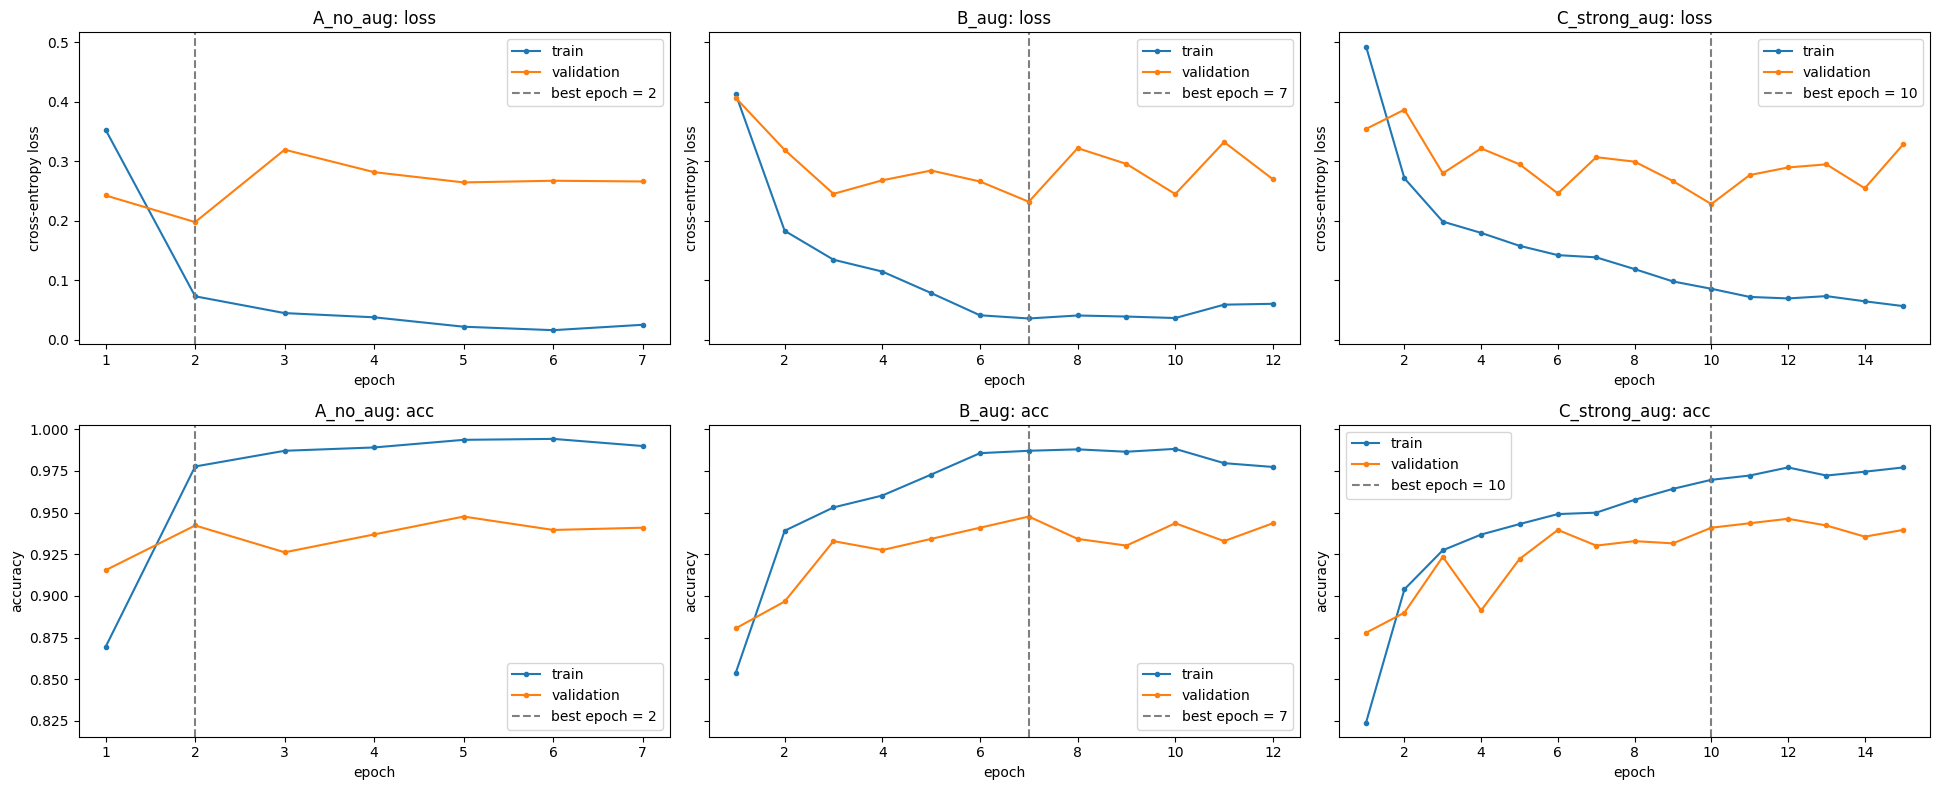

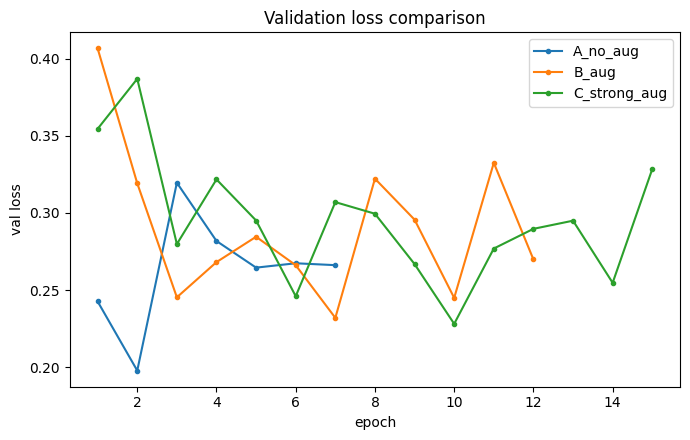

In [46]:
exps = list(histories)
fig, axes = plt.subplots(2, len(exps), figsize=(6.5 * len(exps), 8), sharey="row", squeeze=False)
for j, exp in enumerate(exps):
    h = histories[exp]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    best_ep = int(np.argmin(h["val_loss"])) + 1
    for i, (metric, ylabel) in enumerate([("loss", "cross-entropy loss"), ("acc", "accuracy")]):
        a = axes[i, j]
        a.plot(ep, h[f"train_{metric}"], "o-", ms=3, label="train")
        a.plot(ep, h[f"val_{metric}"], "o-", ms=3, label="validation")
        a.axvline(best_ep, ls="--", c="gray", label=f"best epoch = {best_ep}")
        a.set(title=f"{exp}: {metric}", xlabel="epoch", ylabel=ylabel); a.legend()
plt.tight_layout(); plt.savefig(f"{WORK_DIR}/loss_curves.png", dpi=150); plt.show()

plt.figure(figsize=(7, 4.5))
for exp in exps:
    plt.plot(np.arange(1, len(histories[exp]["val_loss"]) + 1), histories[exp]["val_loss"], "o-", ms=3, label=exp)
plt.title("Validation loss comparison"); plt.xlabel("epoch"); plt.ylabel("val loss"); plt.legend()
plt.tight_layout(); plt.show()

In [47]:
rows = []
for exp, h in histories.items():
    b = int(np.argmin(h["val_loss"]))
    rows.append({
        "experiment": exp,
        "epochs trained": len(h["val_loss"]),
        "best epoch": b + 1,
        "best val loss": h["val_loss"][b],
        "val acc @best": h["val_acc"][b],
        "train loss @best": h["train_loss"][b],
        "gap (val - train loss)": h["val_loss"][b] - h["train_loss"][b],
    })
summary = pd.DataFrame(rows).set_index("experiment")
display(summary.round(4))

FINAL_EXP = summary["best val loss"].idxmin()   # เลือกจาก validation เท่านั้น ห้ามดู test
print("โมเดลสุดท้าย:", FINAL_EXP)

,epochs trained,best epoch,best val loss,val acc @best,train loss @best,gap (val - train loss)
experiment,,,,,,
A_no_aug,7,2,0.1979,0.9423,0.0731,0.1247
B_aug,12,7,0.2320,0.9477,0.0359,0.1962
C_strong_aug,15,10,0.2282,0.9409,0.0858,0.1424


โมเดลสุดท้าย: A_no_aug


## 8. Model Evaluation บน Test Set (โหลด `best.pt` ของโมเดลสุดท้าย, ประเมินครั้งเดียว)

In [48]:
best_model = build_model(pretrained=False)
ckpt = load_checkpoint(ckpt_paths(FINAL_EXP)[1], best_model)
best_model.eval()
print(f"Loaded {FINAL_EXP}/best.pt จาก epoch {ckpt['epoch']} (val loss {ckpt['best_val_loss']:.4f})")

y_true, y_pred = [], []
with torch.no_grad(), torch.amp.autocast("cuda"):
    for x, y in test_loader:
        y_pred.append(best_model(x.to(device)).argmax(1).cpu().numpy())
        y_true.append(y.numpy())
y_true, y_pred = np.concatenate(y_true), np.concatenate(y_pred)

test_acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

json.dump({"final_experiment": FINAL_EXP, "best_epoch": ckpt["epoch"], "test_accuracy": test_acc,
           "report": classification_report(y_true, y_pred, target_names=class_names, output_dict=True)},
          open(f"{WORK_DIR}/test_metrics.json", "w"), indent=2)

Loaded A_no_aug/best.pt จาก epoch 2 (val loss 0.1979)
Test accuracy: 0.9520

              precision    recall  f1-score   support

       Lilly      0.889     0.907     0.898       150
       Lotus      0.935     0.967     0.951       150
      Orchid      0.953     0.940     0.946       150
   Sunflower      1.000     1.000     1.000       150
       Tulip      0.986     0.947     0.966       150

    accuracy                          0.952       750
   macro avg      0.953     0.952     0.952       750
weighted avg      0.953     0.952     0.952       750



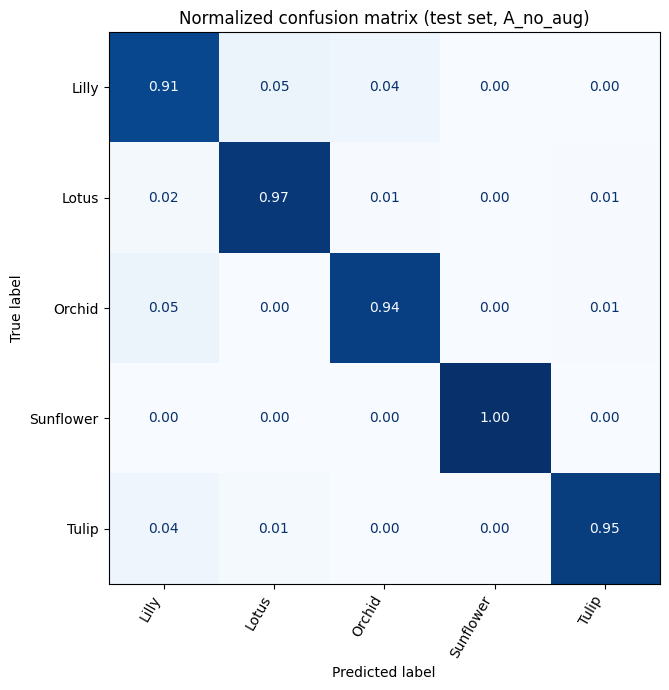

In [49]:
cm = confusion_matrix(y_true, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
plt.xticks(rotation=60, ha="right"); plt.title(f"Normalized confusion matrix (test set, {FINAL_EXP})")
plt.tight_layout(); plt.show()

### ตัวอย่างภาพที่โมเดลทำนายผิด (error analysis)

ทำนายผิด 36 จาก 750 ภาพ


,true,predicted,count
0,Lilly,Lotus,8
1,Orchid,Lilly,8
2,Lilly,Orchid,6
3,Tulip,Lilly,6
4,Lotus,Lilly,3
5,Tulip,Lotus,2
6,Lotus,Orchid,1
7,Lotus,Tulip,1


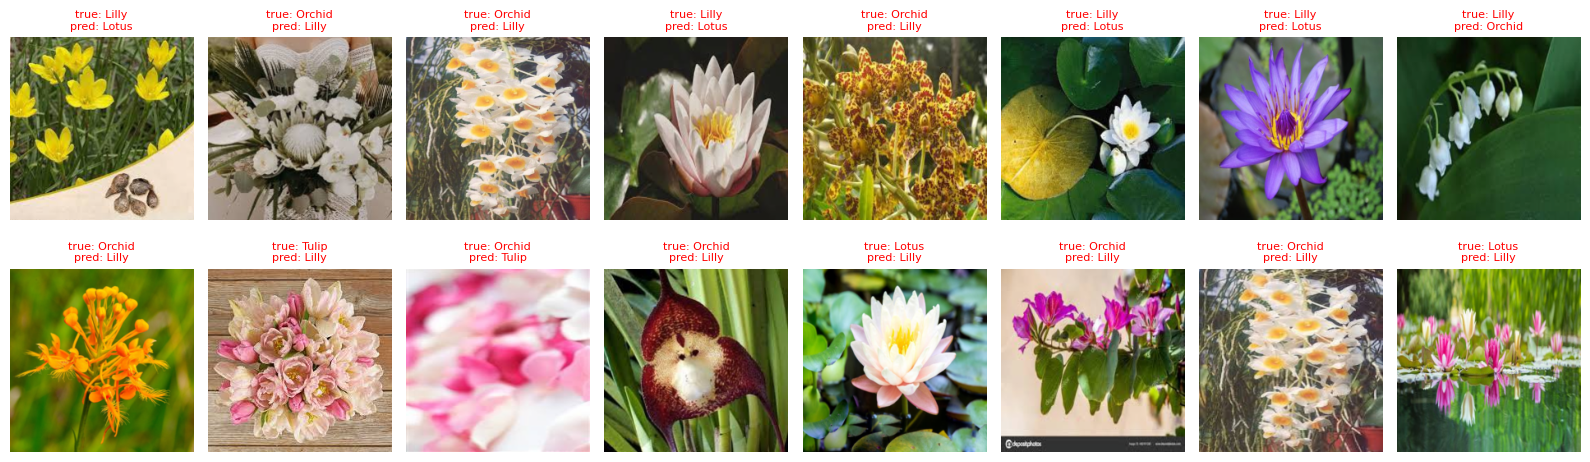

In [50]:
wrong = np.where(y_true != y_pred)[0]
print(f"ทำนายผิด {len(wrong)} จาก {len(y_true)} ภาพ")

cm_raw = confusion_matrix(y_true, y_pred)
pairs = [(class_names[i], class_names[j], cm_raw[i, j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES)
         if i != j and cm_raw[i, j] > 0]
confusions = pd.DataFrame(pairs, columns=["true", "predicted", "count"]).sort_values("count", ascending=False)
display(confusions.head(8).reset_index(drop=True))

if len(wrong):
    show = np.random.default_rng(SEED).choice(wrong, min(16, len(wrong)), replace=False)
    fig, axes = plt.subplots(2, 8, figsize=(16, 5))
    for a in axes.ravel(): a.axis("off")
    for a, i in zip(axes.ravel(), show):
        img, _ = test_ds[i]
        a.imshow(denorm(img))
        a.set_title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]}", fontsize=8, color="red")
    plt.tight_layout(); plt.show()


## 9. อภิปรายผล

In [51]:
# ตัวเลขสรุปสำหรับเขียนอภิปรายผล (คำนวณจากผลรันจริง)
rep = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
f1s = pd.Series({c: rep[c]["f1-score"] for c in class_names}).sort_values()
print(f"โมเดลสุดท้าย: {FINAL_EXP} | test acc = {test_acc:.4f} | macro F1 = {rep['macro avg']['f1-score']:.4f}")
print(f"class ที่ F1 ต่ำสุด: {f1s.index[0]} ({f1s.iloc[0]:.3f}) | สูงสุด: {f1s.index[-1]} ({f1s.iloc[-1]:.3f})\n")
for exp, h in histories.items():
    n, b = len(h["val_loss"]), int(np.argmin(h["val_loss"])) + 1
    stopped = n < CFG["epochs"]
    print(f"{exp:14s} epochs={n:2d}  best_epoch={b:2d}  early_stop={stopped}  "
          f"best_val_loss={h['val_loss'][b-1]:.4f}  train_loss@best={h['train_loss'][b-1]:.4f}  "
          f"gap={h['val_loss'][b-1]-h['train_loss'][b-1]:.4f}")
    if not stopped:
        print(f"   ⚠️ {exp} ไม่ early stop: val loss อาจยังลดอยู่ ควรเพิ่ม CFG['epochs'] แล้วรันใหม่")
print("\nคู่ class ที่สับสนบ่อยสุด:")
display(confusions.head(5).reset_index(drop=True))

โมเดลสุดท้าย: A_no_aug | test acc = 0.9520 | macro F1 = 0.9522
class ที่ F1 ต่ำสุด: Lilly (0.898) | สูงสุด: Sunflower (1.000)

A_no_aug       epochs= 7  best_epoch= 2  early_stop=True  best_val_loss=0.1979  train_loss@best=0.0731  gap=0.1247
B_aug          epochs=12  best_epoch= 7  early_stop=True  best_val_loss=0.2320  train_loss@best=0.0359  gap=0.1962
C_strong_aug   epochs=15  best_epoch=10  early_stop=True  best_val_loss=0.2282  train_loss@best=0.0858  gap=0.1424

คู่ class ที่สับสนบ่อยสุด:


,true,predicted,count
0,Lilly,Lotus,8
1,Orchid,Lilly,8
2,Lilly,Orchid,6
3,Tulip,Lilly,6
4,Lotus,Lilly,3


### 1. การเรียนรู้และการลู่เข้าของโมเดล (Convergence Analysis)
จากการติดตามการเรียนรู้ผ่าน Validation Loss ในทั้ง 3 สภาวะการทดลอง พบว่าจุดลู่เข้า (Convergence) และจุดหยุดการทำงาน (Early Stopping) มีความแตกต่างกันอย่างชัดเจน:
* **Experiment A (No Augmentation):** ลู่เข้าเร็วที่สุด เกิด Best Validation Loss ที่ **Epoch 2 (Val Loss = 0.1979)** และถูก Early Stopping ตัดการทำงานที่ Epoch 7 (เนื่องจาก Val Loss ไม่ปรับตัวดีขึ้นติดต่อกัน 5 Epochs)
* **Experiment B (Data Augmentation):** เกิด Best Validation Loss ที่ **Epoch 7 (Val Loss = 0.2320)** และจบการทำงานที่ Epoch 12
* **Experiment C (Strong Augmentation):** ลู่เข้าช้าที่สุด เกิด Best Validation Loss ที่ **Epoch 10 (Val Loss = 0.2282)** และจบการทำงานที่ Epoch 15

กราฟแสดงให้เห็นว่ายิ่งเพิ่ม Data Augmentation เข้มข้นขึ้น โมเดลยิ่งต้องใช้จำนวน Epoch มากขึ้นในการเรียนรู้ก่อนจะลู่เข้าสู่จุดสมดุล โดยระบบได้ทำการบันทึกไฟล์น้ำหนัก `best.pt` ณ จุดที่ค่า Val Loss ต่ำที่สุดของแต่ละสภาวะไว้ใช้งานต่อเรียบร้อยแล้ว


### 2. การวิเคราะห์ภาวะ Overfitting (Train vs Validation Gap)
เมื่อเปรียบเทียบระยะห่างระหว่าง Train Loss กับ Validation Loss (Generalization Gap) ณ จุด Best Epoch ของแต่ละสภาวะ:
* **Experiment A:** Gap = **0.1247** (Train Loss 0.0731, Val Loss 0.1979)
* **Experiment B:** Gap = **0.1962** (Train Loss 0.0359, Val Loss 0.2320)
* **Experiment C:** Gap = **0.1424** (Train Loss 0.0858, Val Loss 0.2282)

**ข้อสังเกต:** Experiment B แสดงค่า Gap ที่ Best Epoch กว้างที่สุด (0.1962) แต่จำเป็นต้องตีความด้วยความระมัดระวัง เนื่องจากแต่ละสภาวะหยุดที่ Epoch ต่างกัน โดย Experiment A ลู่เข้าเร็วมากหยุดที่ Epoch 2 จึงยังมีระยะห่างไม่มาก แต่เมื่อพิจารณา Experiment A หลัง Epoch 2 พบว่า Train Loss ลดลงต่อเนื่องจาก 0.0731 เหลือ 0.0253 (Epoch 7) ขณะที่ Val Loss เด้งสูงขึ้นจาก 0.1979 เป็น 0.2662 ซึ่งเป็นสัญญาณของการเกิด Overfitting ชัดเจนที่ระบบ Early Stopping ได้ช่วยตัดไว้ก่อน


### 3. ผลของ Data Augmentation ต่อประสิทธิภาพของโมเดล
* **ผลต่อ Validation Loss:** Augmentation ไม่ได้ช่วยลดค่า Val Loss ในการทดลองนี้ โดย Experiment A (0.1979) ทำค่าได้ต่ำกว่าทั้ง B (0.2320) และ C (0.2282)
* **ผลต่อ Validation Accuracy:** ค่าความแม่นยำบน Validation Set ของ A (0.9423), B (0.9477) และ C (0.9409) มีความต่างระหว่าง A และ B เพียงประมาณ 4 ภาพ จากทั้งหมด 745 ภาพ ซึ่งเป็นความแตกต่างเพียงเล็กน้อย **จึงไม่สามารถสรุปได้อย่างมีนัยสำคัญทางสถิติว่า Data Augmentation ช่วยเพิ่มประสิทธิภาพได้ดีกว่า**
* **พฤติกรรมการเรียนรู้ (Loss Curve):** ใน Epoch แรก Train Loss ของ A (0.3531) ต่ำกว่า B (0.4124) และ C (0.4930) ตามลำดับ แสดงว่า Augmentation เพิ่มความยากในการเรียนรู้ให้กับโมเดล

**การวิเคราะห์สาเหตุเชิงลึก:** โมเดล ResNet-18 ซึ่งผ่านการ Pretrain บน ImageNet มีความสามารถในการสกัด Feature สูงอยู่แล้ว และชุดข้อมูล Train (3,499 ภาพ) มีขนาดเพียงพอ การทำ Crop/Rotation/Color Jitter ที่เข้มข้นเกินไปอาจไปตัดเบาะแสสำคัญของภาพ (เช่น รูปทรงกลีบดอกไม้หลุดออกจากกรอบ) ทำให้ภาพ Train มีลักษณะต่างจาก Validation Set ที่เป็นภาพธรรมชาติ 

> **การเลือกโมเดลเพื่อประเมินผล: เลือกโมเดลสุดท้ายจาก val loss ต่ำสุด คือ A_no_aug (best epoch 2, val loss 0.1979)



### 4. ประสิทธิภาพบน Test Set (Test Performance)
การประเมินผลโมเดล Experiment A บนชุดข้อมูลทดสอบ (Test Set) จำนวน 750 ภาพ (ประเมินเพียงครั้งเดียว):
* **Overall Test Accuracy:** **0.9520** (95.20%)
* **Macro Average F1-score:** **0.9522**

| Class | Precision | Recall | F1-score | หมายเหตุ |
| :--- | :---: | :---: | :---: | :--- |
| **Sunflower** | **1.000** | **1.000** | **1.000** | **ดีที่สุด:** จำแนกถูกต้องสมบูรณ์แบบ 100% |
| **Lotus** | - | - | - | ประสิทธิภาพอยู่ในเกณฑ์สูง |
| **Orchid** | - | - | - | ประสิทธิภาพอยู่ในเกณฑ์ดี |
| **Tulip** | - | - | - | ประสิทธิภาพอยู่ในเกณฑ์ดี |
| **Lilly** | 0.889 | 0.907 | **0.898** | **ต่ำที่สุด:** มีความสับสนกับคลาสอื่นมากที่สุด |


### 5. การวิเคราะห์ข้อผิดพลาดของโมเดล (Error Analysis)
โมเดลทำนายผิดพลาดรวม **36 จาก 750 ภาพ** (คิดเป็น Error Rate 4.8%) จากการวิเคราะห์ Matrix การทายผิดพบรูปแบบความสับสนหลักๆ ดังนี้:

* **คู่ Class ที่โมเดลสับสนบ่อยที่สุด:**
  1. **Lilly → ทายว่าเป็น Lotus:** จำนวน 8 ภาพ
  2. **Orchid → ทายว่าเป็น Lilly:** จำนวน 8 ภาพ
  3. **Lilly → ทายว่าเป็น Orchid:** จำนวน 6 ภาพ
  4. **Tulip → ทายว่าเป็น Lilly:** จำนวน 6 ภาพ
  5. **Lotus → ทายว่าเป็น Lilly:** จำนวน 3 ภาพ


### 6. แนวทางปรับปรุงและข้อจำกัด
**ข้อจำกัดของการทดลอง**
* **ภาพถูกบีบสัดส่วน:** ภาพต้นฉบับมีขนาด/สัดส่วนหลากหลาย (เช่น 275×183, 300×168) แต่ถูก `Resize((224, 224))` โดยตรง ทำให้รูปทรงกลีบดอกบิดเบี้ยว
* **Seed เดียว:** ทุกการทดลองใช้ `SEED = 42` (ทั้งการแบ่งข้อมูลและการเริ่มต้นน้ำหนัก) ผลต่างเล็ก ๆ ระหว่าง A, B, C จึงอาจเป็นความผันผวนจากการสุ่มได้
* **ภาพซ้ำ:** ตรวจเฉพาะไฟล์ที่เหมือนกันทุกไบต์ ภาพที่คล้ายกันมากแต่ไม่เหมือนกันยังอาจปนอยู่ข้าม split

**ถ้ามีเวลาเพิ่มจะทดลองต่อ**
1. **Resize แบบคงสัดส่วน** (resize ด้านสั้นแล้ว center crop หรือ pad) เพื่อดูว่าการบิดสัดส่วนมีผลหรือไม่
2. **รันหลาย seed** (เช่น 3–5 seed) แล้วเทียบค่าเฉลี่ยและส่วนเบี่ยงเบนของ val loss ของ A/B/C ก่อนสรุปว่า augmentation ช่วยหรือไม่
3. **ปรับความแรงของ augmentation** ให้อ่อนลงหรือเลือกเฉพาะแบบที่ช่วย (เช่น พลิกซ้ายขวา + ปรับแสง) และทดลองโมเดลอื่น (เช่น EfficientNet) เพื่อดูว่าข้อสรุปเปลี่ยนหรือไม่


## 10. ขั้นตอนส่งลิงก์ (ทำตามทุกข้อ)
1. ตรวจว่า Accelerator เป็น **GPU** และ `USE_DEMO = False`
2. ลบโฟลเดอร์ `checkpoints` เก่าก่อนรันเต็ม (หรือ Restart session) เพื่อให้เห็นการเทรนตั้งแต่ epoch 1 และการ resume
3. กด **Save Version** > เลือก **Save & Run All (Commit)** > รอจนสถานะเป็น **Successful**
4. เปิดหน้า notebook เวอร์ชันนั้น ตรวจว่าผลลัพธ์ทุกเซลล์และกราฟแสดงครบ
5. **Share** > ตั้งค่าเป็น **Public** > คัดลอกลิงก์
6. ถ้ากลุ่มอัปโหลดชุดข้อมูลเอง ต้องตั้ง **dataset เป็น Public ด้วย**
7. **เปิดลิงก์ใน Incognito/Private window** ถ้าเห็น notebook พร้อมผลลัพธ์ได้ จึงส่งลิงก์

> **ลิงก์เปิดไม่ได้ = 0 คะแนน ไม่มีการแก้ไขหลังกำหนดส่ง**

---
## Part 2: Big Data + Machine Learning
ดูไฟล์แยก